# Step 1 — PPO with continuous actions (sanity check on Pendulum)

Starting point: our PPO from the course (TD6, discrete actions on LunarLander).
EvoGym robots need one **real number per actuator** at every step, so the policy must output continuous actions.

Changes vs TD6 (marked `# CHANGED` / `# ADDED` in the code):
1. **Network**: the actor head outputs the mean μ of a Gaussian (no softmax) + a learned `log_std` parameter.
2. **Distribution**: `Normal(μ, σ)` instead of `Categorical`; log-probs and entropy are **summed** over action dimensions.
3. **Action bounds**: the policy acts around [-1, 1]; actions are clipped and rescaled to the env bounds just before `env.step`. The buffer stores the **unclipped** action so the PPO ratio stays correct.
4. **Test**: deterministic action = μ (instead of `argmax`).
5. **Hyperparameters**: TD6 defaults, `entropy_beta = 0` (σ already drives exploration).

Why Pendulum first: 1 continuous action, trains in minutes, known target (random ≈ −1200 to −1600 per episode, solved ≈ −200).
If PPO fails here, the bug is in PPO, not in EvoGym.

In [1]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from pathlib import Path

## Actor-critic network (Gaussian policy)

In [2]:
class ActorCriticNetwork(nn.Module):
    def __init__(self, state_size, action_size, hidden_size=128):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
        )
        self.actor = nn.Linear(hidden_size, action_size)      # CHANGED: mean μ of a Gaussian, no softmax
        self.critic = nn.Linear(hidden_size, 1)
        self.log_std = nn.Parameter(torch.zeros(action_size))  # ADDED: learned log σ (state-independent)

    def forward(self, x):
        features = self.shared(x)
        mean = self.actor(features)
        state_value = self.critic(features)
        return mean, self.log_std.expand_as(mean), state_value  # CHANGED: (μ, log σ, V) instead of (probs, V)

## PPO agent

In [3]:
class PPOAgent:
    def __init__(
        self, lr=3e-4, gamma=0.99, state_size=3, action_size=1,
        gae_lambda=0.95, entropy_beta=0.0, clip_epsilon=0.2, ppo_epochs=10, batch_size=64
    ):
        # Hyperparameters
        self.lr = lr
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.entropy_beta = entropy_beta
        self.clip_epsilon = clip_epsilon
        self.ppo_epochs = ppo_epochs
        self.batch_size = batch_size

        # Environment parameters
        self.state_size = state_size
        self.action_size = action_size  # CHANGED: number of action dimensions (was n_actions)

        # Tiny MLP: CPU is faster than MPS on a Mac
        self.device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
        print(f"Using device: {self.device}")

        self.network = ActorCriticNetwork(state_size, action_size).to(self.device)
        self.optimizer = optim.Adam(self.network.parameters(), lr=lr)
        self.reset_memory()

    def reset_memory(self):
        """Clear rollout buffers."""
        self.states = []
        self.actions = []
        self.rewards = []
        self.values = []
        self.dones = []
        self.log_probs = []

    def get_dist(self, states):
        """ADDED: Gaussian policy distribution and state values for a batch of states."""
        mean, log_std, value = self.network(states)
        return torch.distributions.Normal(mean, log_std.exp()), value

    def choose_action(self, state):
        """Sample an action from the current policy given the state."""
        state_tensor = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
        with torch.no_grad():
            dist, value = self.get_dist(state_tensor)    # CHANGED: Normal instead of Categorical
        action = dist.sample()                            # shape (1, action_size)
        log_prob = dist.log_prob(action).sum(-1)          # CHANGED: sum over independent action dims
        return action.squeeze(0).cpu().numpy(), value.item(), log_prob.item()  # CHANGED: action is a vector

    def store(self, state, action, reward, value, done, log_prob):
        """Store a transition; done marks termination OR time-limit truncation.

        The training loop adds the bootstrap value to time-limit rewards.
        """
        self.states.append(state)
        self.actions.append(action)
        self.rewards.append(reward)
        self.values.append(value)
        self.dones.append(done)
        self.log_probs.append(log_prob)

    def compute_gae(self, next_value):
        """Compute returns and advantages with GAE (unchanged from TD6)."""
        rewards = np.array(self.rewards, dtype=np.float32)
        values = np.array(self.values + [next_value], dtype=np.float32)
        dones = np.array(self.dones, dtype=np.float32)

        T = len(rewards)
        returns = np.zeros(T, dtype=np.float32)
        advantages = np.zeros(T, dtype=np.float32)

        gae = 0.0
        for t in reversed(range(T)):
            delta = rewards[t] + self.gamma * values[t + 1] * (1.0 - dones[t]) - values[t]
            gae = delta + self.gamma * self.gae_lambda * (1.0 - dones[t]) * gae
            advantages[t] = gae
            returns[t] = advantages[t] + values[t]

        return returns, advantages

    def update(self, next_value):
        """Perform one PPO update step."""
        if len(self.states) == 0:
            return {"actor_loss": 0.0, "critic_loss": 0.0}

        returns, advantages = self.compute_gae(next_value)

        states = torch.tensor(np.array(self.states), dtype=torch.float32, device=self.device)       # (N, state_size)
        actions = torch.tensor(np.array(self.actions), dtype=torch.float32, device=self.device)     # CHANGED: (N, action_size) floats
        returns = torch.tensor(returns, dtype=torch.float32, device=self.device)                    # (N,)
        advantages = torch.tensor(advantages, dtype=torch.float32, device=self.device)              # (N,)
        old_log_probs = torch.tensor(np.array(self.log_probs), dtype=torch.float32, device=self.device)  # (N,)

        if advantages.numel() > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        total_actor_loss = 0
        total_critic_loss = 0
        updates = 0

        for _ in range(self.ppo_epochs):
            indices = torch.randperm(len(states))
            for start in range(0, len(states), self.batch_size):
                idx = indices[start:start + self.batch_size]

                batch_states = states[idx]
                batch_actions = actions[idx]
                batch_old_log_probs = old_log_probs[idx]
                batch_returns = returns[idx]
                batch_advantages = advantages[idx]

                dist, values = self.get_dist(batch_states)               # CHANGED: Normal
                log_probs = dist.log_prob(batch_actions).sum(-1)         # CHANGED: sum over action dims
                entropy = dist.entropy().sum(-1).mean()                  # CHANGED: sum over action dims

                ratio = torch.exp(log_probs - batch_old_log_probs)
                surr1 = ratio * batch_advantages
                surr2 = torch.clamp(ratio, 1 - self.clip_epsilon, 1 + self.clip_epsilon) * batch_advantages
                actor_loss = -torch.min(surr1, surr2).mean()

                critic_loss = F.mse_loss(values.squeeze(-1), batch_returns)

                loss = actor_loss + 0.5 * critic_loss - self.entropy_beta * entropy

                self.optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.network.parameters(), 0.5)
                self.optimizer.step()

                total_actor_loss += actor_loss.item()
                total_critic_loss += critic_loss.item()
                updates += 1

        self.reset_memory()

        return {
            'actor_loss': total_actor_loss / updates,
            'critic_loss': total_critic_loss / updates
        }

## Action rescaling

The policy acts around [-1, 1]. Clip and rescale to the environment bounds (Pendulum: [-2, 2]; EvoGym: [0.6, 1.6]) **only when stepping the env**.

In [4]:
def to_env_action(action, action_space):
    """ADDED: map a policy action in [-1, 1] to [low, high] of the environment."""
    a = np.clip(action, -1.0, 1.0)
    return action_space.low + (a + 1.0) * 0.5 * (action_space.high - action_space.low)


# Self-check: the bounds map to the env bounds
_space = gym.spaces.Box(-2.0, 2.0, (1,))
assert np.allclose(to_env_action(np.array([-1.0]), _space), -2.0)
assert np.allclose(to_env_action(np.array([5.0]), _space), 2.0)   # clipped
assert np.allclose(to_env_action(np.array([0.0]), _space), 0.0)

## Training loop

In [5]:
def train_agent(episodes=1000, update_freq=2048, env_id="Pendulum-v1",
                lr=3e-4, gamma=0.99, gae_lambda=0.95, entropy_beta=0.0,
                clip_epsilon=0.2, ppo_epochs=10, batch_size=64, seed=31):
    """Train a PPO agent. PPO collects 'update_freq' transitions before its mini-batch updates."""
    if episodes < 1 or update_freq < 1:
        raise ValueError("episodes and update_freq must be positive.")

    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make(env_id)
    sample_state, _ = env.reset()
    state_size = len(sample_state)
    action_size = env.action_space.shape[0]   # CHANGED: continuous action dimensions
    print(f"State size: {state_size}, Action size: {action_size}, bounds {env.action_space.low}..{env.action_space.high}")

    agent = PPOAgent(state_size=state_size, action_size=action_size, lr=lr, gamma=gamma,
                     gae_lambda=gae_lambda, entropy_beta=entropy_beta, clip_epsilon=clip_epsilon,
                     ppo_epochs=ppo_epochs, batch_size=batch_size)

    rewards_history, actor_loss_history, critic_loss_history = [], [], []
    std_history = []  # ADDED: policy σ after each update (exploration should shrink)

    print(f"Training PPO on {env_id} for {episodes} episodes...")
    print("=" * 60)

    steps_since_update = 0
    for ep in range(episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        done = False
        ep_reward = 0.0

        while not done:
            action, value, log_prob = agent.choose_action(state)
            next_state, reward, terminated, truncated, _ = env.step(to_env_action(action, env.action_space))  # CHANGED
            done = terminated or truncated

            # Bootstrap a time limit from its final observation, then stop GAE at the episode boundary.
            stored_reward = reward
            if truncated and not terminated:
                with torch.no_grad():
                    next_tensor = torch.as_tensor(next_state, dtype=torch.float32, device=agent.device).unsqueeze(0)
                    stored_reward += agent.gamma * agent.network(next_tensor)[2].item()  # CHANGED: value is output [2]
            agent.store(state, action, stored_reward, value, done, log_prob)  # unclipped action stored
            state = next_state
            ep_reward += reward
            steps_since_update += 1

            if steps_since_update >= update_freq or (done and ep + 1 == episodes):
                with torch.no_grad():
                    next_tensor = torch.as_tensor(next_state, dtype=torch.float32, device=agent.device).unsqueeze(0)
                    next_value = 0.0 if done else agent.network(next_tensor)[2].item()
                losses = agent.update(next_value)
                steps_since_update = 0
                actor_loss_history.append(losses["actor_loss"])
                critic_loss_history.append(losses["critic_loss"])
                std_history.append(agent.network.log_std.exp().mean().item())

        rewards_history.append(ep_reward)

        if (ep + 1) % 50 == 0:
            avg100 = np.mean(rewards_history[-100:])
            print(f"Ep {ep+1}: Avg100 = {avg100:.1f}, Last = {ep_reward:.1f}, sigma = {std_history[-1] if std_history else 1:.3f}")

    env.close()
    print("=" * 60)
    print("Training complete!")
    return agent, rewards_history, actor_loss_history, critic_loss_history, std_history

## Test (deterministic policy)

In [6]:
def test_agent(agent, env_id="Pendulum-v1", episodes=5, seed=0):
    """Run a trained PPO agent in test mode: action = mean μ (CHANGED: was argmax)."""
    env = gym.make(env_id)
    totals = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        done, total_r = False, 0.0
        while not done:
            s_t = torch.as_tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
            with torch.no_grad():
                mean, _, _ = agent.network(s_t)
            state, r, terminated, truncated, _ = env.step(to_env_action(mean.squeeze(0).cpu().numpy(), env.action_space))
            done = terminated or truncated
            total_r += r
        totals.append(total_r)
        print(f"Test Episode {ep+1}: {total_r:.1f}")
    env.close()
    return totals

## Plotting (reused from TD6)

In [7]:
def _moving_avg(x, window):
    """Return the moving average aligned with the original sample indices."""
    x = np.asarray(x, dtype=float)
    if len(x) < window or window == 1:
        return np.arange(len(x)), x
    moving_avg = np.convolve(x, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(x)), moving_avg


def plot_results(
    rewards,
    actor_losses=None,
    critic_losses=None,
    reward_window=100,
    loss_window=100,
    solved_y=200,
    save_path=None,
    loss_log_scale=False,
):
    """Plot raw curves on the left and moving averages on the right.

    Rewards are recorded per episode; losses are recorded per agent update.
    Short histories are displayed without smoothing.
    """
    if reward_window < 1 or loss_window < 1:
        raise ValueError("Moving-average windows must be positive.")

    rows = [(rewards, "Train Reward", "Episode", "Total Reward", "Avg Reward", reward_window)]
    if actor_losses is not None:
        rows.append((actor_losses, "Actor Loss", "Update", "Loss", "Avg Loss", loss_window))
    if critic_losses is not None:
        rows.append((critic_losses, "Critic Loss", "Update", "Loss", "Avg Loss", loss_window))

    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 4.6 * len(rows)), squeeze=False)

    for row, (values, title, xlabel, ylabel, avg_ylabel, window) in enumerate(rows):
        raw_ax, avg_ax = axes[row]

        # Raw values (left column).
        raw_ax.plot(values, alpha=0.4)
        raw_ax.set_title(f"{title} per {xlabel}")
        raw_ax.set_ylabel(ylabel)

        # Moving average (right column), aligned with the original indices.
        indices, moving_avg = _moving_avg(values, window)
        avg_ax.plot(indices, moving_avg)
        if len(values) >= window and window > 1:
            avg_ax.set_title(f"Moving Avg {title} (window={window})")
        else:
            avg_ax.set_title(f"{title} (no smoothing)")
        avg_ax.set_ylabel(avg_ylabel)

        for ax in (raw_ax, avg_ax):
            ax.set_xlabel(xlabel)
            ax.grid(True)
            if row == 0:
                if solved_y is not None:
                    ax.axhline(solved_y, color="gray", linestyle="--", linewidth=1,
                               label=f"Reward reference ({solved_y:g})")
                    ax.legend()
            else:
                ax.axhline(0, color="gray", linestyle="--", linewidth=1)
                if loss_log_scale:
                    # Actor losses may be negative, so a signed log scale is needed.
                    ax.set_yscale("symlog")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    plt.show()


## Run: Pendulum, TD6 hyperparameters, 1000 episodes (= 200k steps)

State size: 3, Action size: 1, bounds [-2.]..[2.]
Using device: cpu


Training PPO on Pendulum-v1 for 1000 episodes...


Ep 50: Avg100 = -1214.8, Last = -1556.0, sigma = 0.987


Ep 100: Avg100 = -1243.6, Last = -1279.4, sigma = 0.944


Ep 150: Avg100 = -1242.5, Last = -1121.5, sigma = 0.925


Ep 200: Avg100 = -1223.1, Last = -1717.6, sigma = 0.887


... (12 outputs left out)

Ep 850: Avg100 = -637.7, Last = -517.5, sigma = 0.453


Ep 900: Avg100 = -506.3, Last = -550.8, sigma = 0.438


Ep 950: Avg100 = -459.3, Last = -533.5, sigma = 0.436


Ep 1000: Avg100 = -708.8, Last = -1388.3, sigma = 0.439
Training complete!

Final avg (last 100): -708.8
Max reward: -7.5


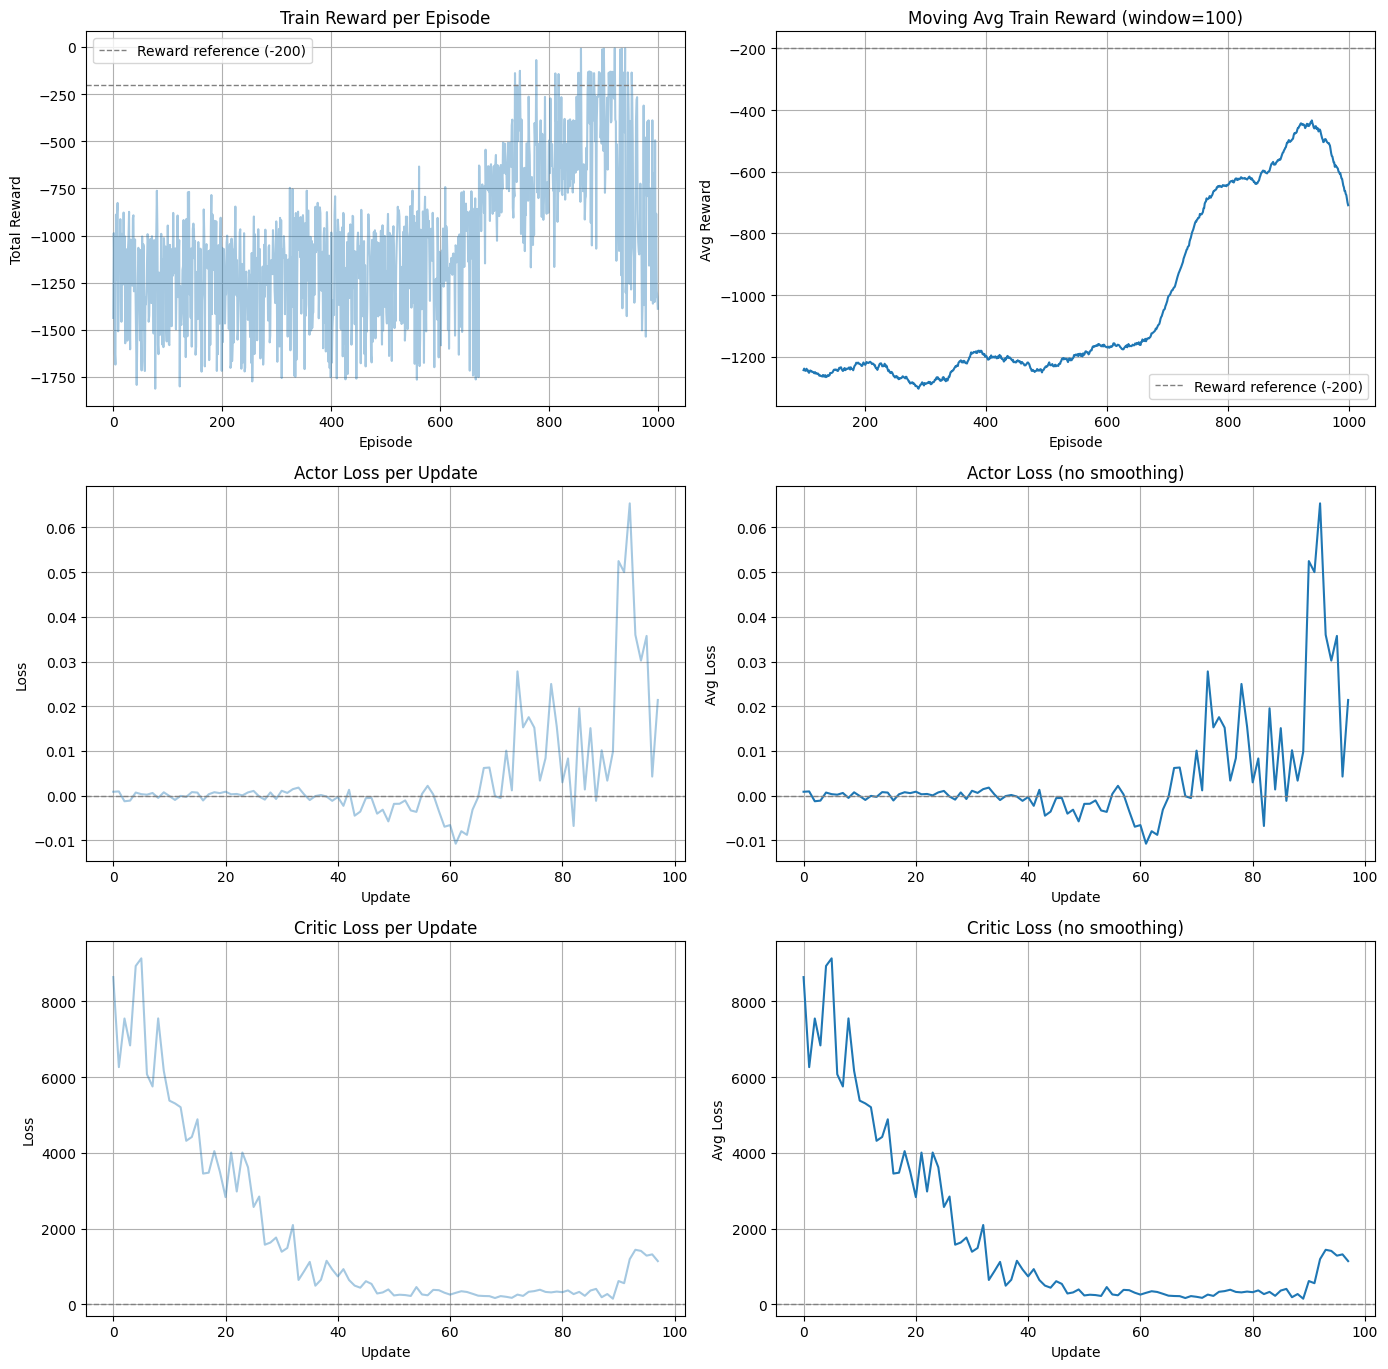

In [8]:
seed = 31
agent, rewards, actor_losses, critic_losses, stds = train_agent(
    episodes=1000, update_freq=2048, env_id="Pendulum-v1", seed=seed,
    lr=3e-4, gamma=0.99, gae_lambda=0.95, entropy_beta=0.0,
    clip_epsilon=0.2, ppo_epochs=10, batch_size=64,
)
print(f"\nFinal avg (last 100): {np.mean(rewards[-100:]):.1f}")
print(f"Max reward: {max(rewards):.1f}")

Path("../figures").mkdir(exist_ok=True)
plot_results(rewards, actor_losses=actor_losses, critic_losses=critic_losses,
             solved_y=-200, save_path="../figures/01_pendulum_td6_defaults.png")

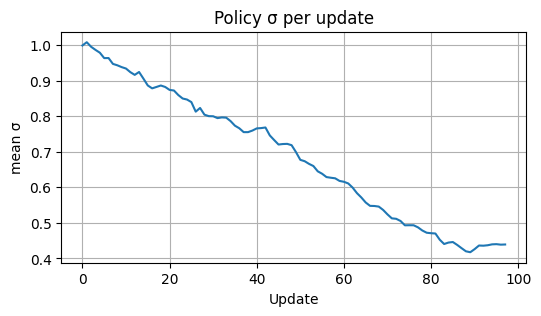

Test Episode 1: -509.8
Test Episode 2: -507.7
Test Episode 3: -262.7
Test Episode 4: -1499.6
Test Episode 5: -1387.7
Mean test return: -833.5


In [9]:
plt.figure(figsize=(6, 3))
plt.plot(stds)
plt.title("Policy σ per update")
plt.xlabel("Update"); plt.ylabel("mean σ"); plt.grid(True)
plt.show()

test_scores = test_agent(agent, episodes=5)
print(f"Mean test return: {np.mean(test_scores):.1f}")